# Lab 9 Walkthrough: Raster Data

A **raster** is a grid of equally sized cells. Each cell holds one value. This lab uses rasters of Dallas County to open a grid, read what the file says about itself, clean and reshape it, compute new grids from old ones, and summarize a grid into census tracts.

**How to use this notebook.** Run it top to bottom. Each part has a short explanation, code, and a **Try it yourself** box that is not graded. The graded work is in `lab9-tasks.ipynb`.

**Data (all in `data/`).**

| File | What it is |
|---|---|
| `dallas_pop_2020.tif` | Residents per cell, 100 m cells. GHS-POP 2020 (GHSL, European Commission Joint Research Centre). A modeled estimate, not a count |
| `dallas_pop_2020_raw.tif` | The same grid with the cells outside the county set to the nodata value -200, as GHSL stores it |
| `dallas_built_v_2020.tif` | Built-up volume in cubic meters per cell, same grid. GHS-BUILT-V 2020 |
| `dallas_landcover_2021.tif` | Land cover class code per 10 m cell. ESA WorldCover 2021 |
| `dallas_dem_glo30.tif` | Elevation in meters, about 30 m cells. Copernicus GLO-30 |
| `dallas_s2_2025-09-17.tif` | Sentinel-2 satellite image, four bands (blue, green, red, near-infrared), 10 m cells, a 15 km square around downtown, 17 September 2025 |
| `dallas_tracts_acs2024.gpkg` | 588 census tracts with the ACS 2020-2024 population (`pop_total`) |

## Part 0. Setup

The first lines of the next cell point GDAL (the library under `rasterio`) at the right PROJ database, which fixes the error "Cannot find proj.db" on some systems. Run that cell before anything else.

`rioxarray` opens a GeoTIFF as an `xarray.DataArray`: an array of values with named dimensions and coordinates, plus the geographic information (CRS and transform) in the `.rio` accessor. `geopandas` reads the tracts.

In [1]:
import os, sys, importlib.util

# Some installs point GDAL at a missing or mismatched PROJ database ("Cannot find proj.db").
# Point it at the database that ships with rasterio, or the environment's own, before rasterio loads.
# this is very much an I-GUIDE Platform kernel issue, if you install with Conda you shouldn't have it.
for d in (os.path.join(os.path.dirname(importlib.util.find_spec("rasterio").origin), "proj_data"),
          os.path.join(sys.prefix, "share", "proj")):
    if os.path.exists(os.path.join(d, "proj.db")):
        os.environ["PROJ_DATA"] = os.environ["PROJ_LIB"] = d
        break

import numpy as np
import pandas as pd
import geopandas as gpd
import rioxarray
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch

print("rioxarray", rioxarray.__version__, "| geopandas", gpd.__version__)

rioxarray 0.22.0 | geopandas 1.1.3


In [2]:
SEQ = "Purples"
ELEV = LinearSegmentedColormap.from_list("elev", ["#F5F3FB", "#2563EB", "#1E1B2E"])
NDVI_CM = LinearSegmentedColormap.from_list("ndvi", ["#DB2777", "#F5F3FB", "#059669"])


def extent(da):
    """Plot extent (left, right, bottom, top) of a raster, in its own coordinates."""
    left, bottom, right, top = da.rio.bounds()
    return (left, right, bottom, top)


def show(da, ax, title, cmap=SEQ, label="", **kw):
    """Draw a 2-D raster with a colorbar."""
    im = ax.imshow(da.values, cmap=cmap, extent=extent(da), **kw)
    ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label=label)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    return im

## Part 1. Open a raster and read its grid

`rioxarray.open_rasterio` returns an array with dimensions `(band, y, x)`. A single-band file has one band, so `squeeze(drop=True)` removes that dimension and leaves `(y, x)`: rows and columns. `masked=True` turns nodata cells into `NaN` (not a number), which Part 2 explains.

In [3]:
pop = rioxarray.open_rasterio("data/dallas_pop_2020.tif", masked=True).squeeze(drop=True)
tracts = gpd.read_file("data/dallas_tracts_acs2024.gpkg").to_crs(pop.rio.crs)
county = tracts.dissolve()
print(pop.dims, pop.shape, pop.rio.crs.to_string())

('y', 'x') (556, 775) ESRI:54009


In [4]:
print("rows, columns:", pop.shape)
print("cell size (x, y) in meters:", pop.rio.resolution())
print("extent (left, bottom, right, top):", pop.rio.bounds())
print("CRS:", pop.rio.crs.to_string())
print("one cell covers", abs(pop.rio.resolution()[0] * pop.rio.resolution()[1]) / 1e6, "square km")
print(pop.rio.transform())

rows, columns: (556, 775)
cell size (x, y) in meters: (100.0, -100.0)
extent (left, bottom, right, top): (-8750300.0, 3938200.0, -8672800.0, 3993800.0)
CRS: ESRI:54009
one cell covers 0.01 square km
| 100.00, 0.00,-8750300.00|
| 0.00,-100.00, 3993800.00|
| 0.00, 0.00, 1.00|


**The transform.** A raster stores no coordinates for its cells. It stores the position of the upper-left corner and the cell size, and every cell's location follows from its row and column:

$$x = x_0 + w \cdot \text{col} \qquad y = y_0 + h \cdot \text{row}$$

- $x_0, y_0$: the x and y coordinates of the upper-left corner of the grid.
- $w$: the cell width in meters (100 here).
- $h$: the cell height, negative (-100 here) because row numbers increase downward while y increases upward.
- col, row: the column and row number of a cell, counted from 0 at the upper left. The formula gives the cell's upper-left corner.

Together with the CRS (Mollweide, ESRI:54009, an equal-area projection in meters), these six numbers place the grid on the Earth. Worked example for row 48, column 492:

In [5]:
t = pop.rio.transform()
row, col = 48, 492
print("x =", t.c, "+", t.a, "*", col, "=", t.c + t.a * col)
print("y =", t.f, "+", t.e, "*", row, "=", t.f + t.e * row)

x = -8750300.0 + 100.0 * 492 = -8701100.0
y = 3993800.0 + -100.0 * 48 = 3989000.0


**What is one number?** Here is a 12 by 12 patch of cells, starting at that row and column, as numbers and as a map. Each number is the estimated residents in one 100 m by 100 m cell.

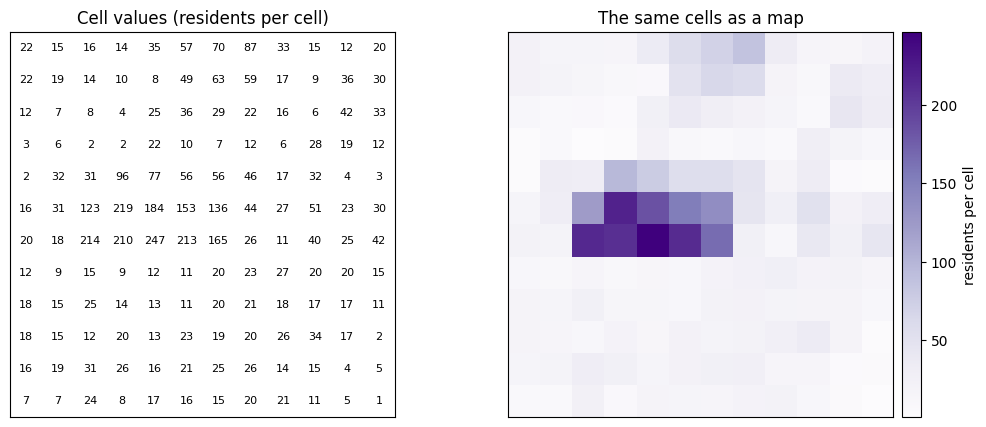

residents in the patch: 4806


In [6]:
patch = pop.values[48:60, 492:504]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for r in range(12):
    for c in range(12):
        ax[0].text(c + .5, 11.5 - r, f"{patch[r, c]:.0f}", ha="center", va="center", fontsize=8)
ax[0].set_xlim(0, 12); ax[0].set_ylim(0, 12); ax[0].set_aspect("equal"); ax[0].set_title("Cell values (residents per cell)")
im = ax[1].imshow(patch, cmap=SEQ)
fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.02, label="residents per cell")
ax[1].set_title("The same cells as a map")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.show()
print("residents in the patch:", round(float(patch.sum())))

**🔎 Try it yourself.** Change `48:60, 492:504` to `100:112, 300:312`. How does the patch change? Which values stay near zero, and what could a block of zeros be?

Now the whole grid. Zeros are masked so the empty cells stay white. The color scale stops at the 99th percentile of the nonzero cells so a few very large cells do not wash out everything else.

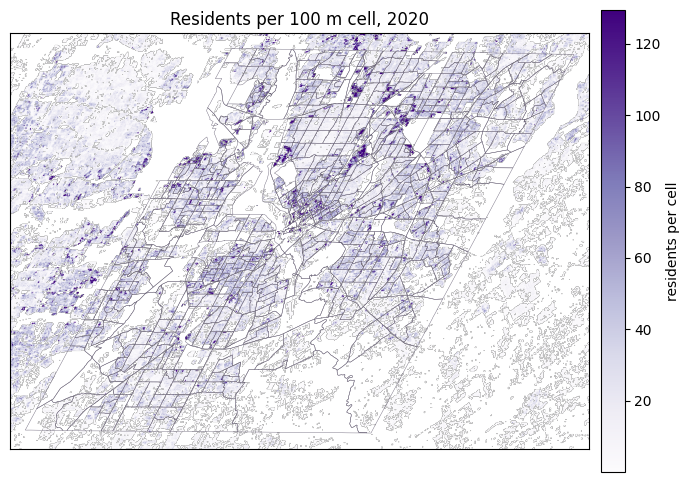

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
nonzero = pop.where(pop > 0)
show(nonzero, ax, "Residents per 100 m cell, 2020", label="residents per cell",
     vmax=float(np.nanpercentile(nonzero.values, 99)))
tracts.boundary.plot(ax=ax, color="#6B6478", linewidth=0.3)
plt.show()

## Part 2. Nodata and summary statistics

**Nodata** is a value that means "no measurement here". GHSL stores it as -200. The raw file `dallas_pop_2020_raw.tif` has every cell outside the county set to -200. If you read that number as data, every statistic is wrong. `masked=True` converts nodata cells to `NaN`, and `xarray` skips `NaN` when it averages.

In [8]:
raw = rioxarray.open_rasterio("data/dallas_pop_2020_raw.tif", masked=False).squeeze(drop=True)
masked = rioxarray.open_rasterio("data/dallas_pop_2020_raw.tif", masked=True).squeeze(drop=True)
print("nodata value:", raw.rio.nodata)
print("mean with nodata left in:", round(raw.mean().item(), 1))
print("mean with nodata masked: ", round(masked.mean().item(), 1))
print("share of cells that are nodata:", round(float(masked.isnull().mean()), 2))

nodata value: -200.0
mean with nodata left in: -91.7
mean with nodata masked:  11.8
share of cells that are nodata: 0.49


**🔎 Try it yourself.** Compute `raw.sum()` and `masked.sum()`. Why are they so different, and why is the sum of the masked grid the one to report?

**Summary statistics and the shape of the values.** Back to the grid with no nodata. A population grid has many cells with zero residents and a few with hundreds, so the mean describes almost no individual cell.

min:    0.0
max:    4588
mean:   9.6
median: 0.0
share of cells with 0 residents: 0.5
total residents in the window:   4125256


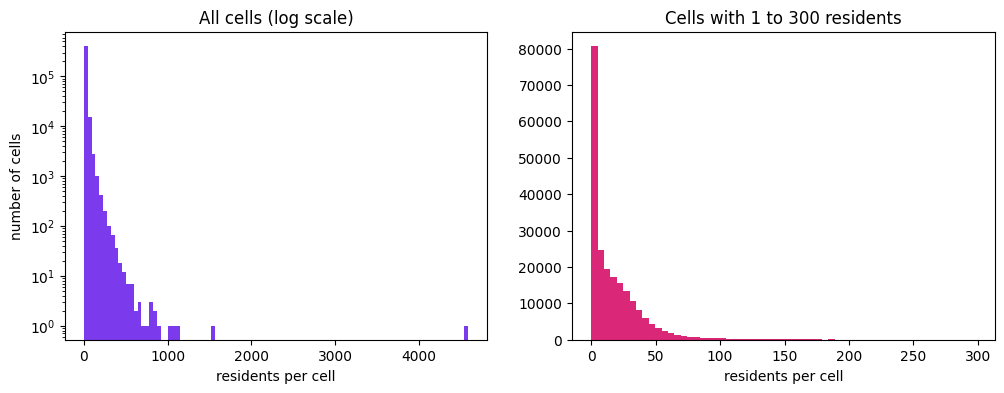

In [9]:
print("min:   ", pop.min().item())
print("max:   ", round(pop.max().item()))
print("mean:  ", round(pop.mean().item(), 1))
print("median:", round(pop.median().item(), 2))
print("share of cells with 0 residents:", round(float((pop == 0).mean()), 2))
print("total residents in the window:  ", round(float(pop.sum())))

v = pop.values.ravel()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(v, bins=100, color="#7C3AED"); ax[0].set_yscale("log")
ax[0].set_title("All cells (log scale)"); ax[0].set_xlabel("residents per cell"); ax[0].set_ylabel("number of cells")
ax[1].hist(v[(v > 0) & (v <= 300)], bins=60, color="#DB2777")
ax[1].set_title("Cells with 1 to 300 residents"); ax[1].set_xlabel("residents per cell")
plt.show()

The total of 4.1 million is larger than the population of the tracts in this lab because the window is a rectangle around them and includes parts of neighboring counties. Part 3 clips to the tracts.

## Part 3. Clip and reproject

**Clipping** keeps only the cells inside a polygon. `pop.rio.clip(geometry)` needs the polygon and the raster in the same CRS. We already converted the tracts to the grid's CRS in Part 1, and `county` is those 588 tracts merged into one polygon. The tract file leaves out some tracts, which show as holes in the outline.

(556, 775) -> (514, 734)
residents before: 4125256  after: 2591862


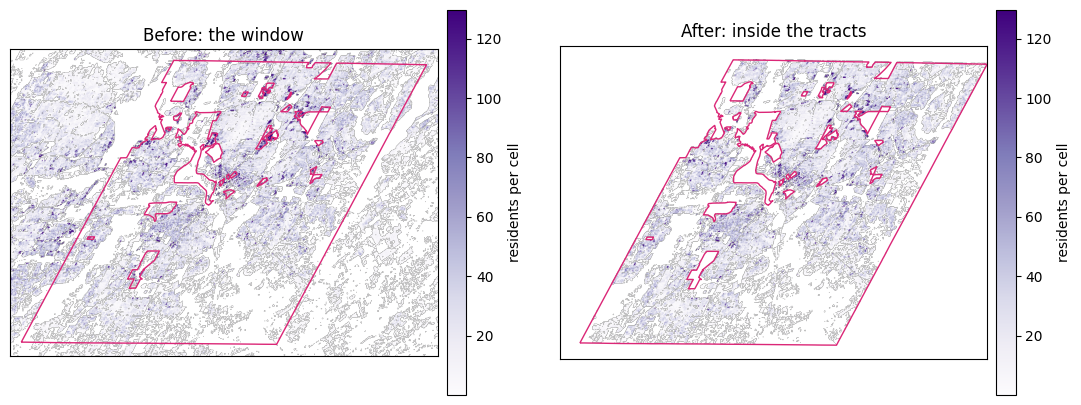

In [10]:
inside = pop.rio.clip(county.geometry)
print(pop.shape, "->", inside.shape)
print("residents before:", round(float(pop.sum())), " after:", round(float(inside.sum())))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, da, t in [(ax[0], pop, "Before: the window"), (ax[1], inside, "After: inside the tracts")]:
    show(da.where(da > 0), a, t, label="residents per cell", vmax=float(np.nanpercentile(pop.values, 99.5)))
    county.boundary.plot(ax=a, color="#DB2777", linewidth=1)
plt.show()

**Reprojecting** moves a raster to a new CRS and builds a new grid. The elevation file is in latitude and longitude (EPSG:4326). Its cells are 0.000278 degrees wide, and a degree of longitude is shorter than a degree of latitude away from the equator, so those cells are not square on the ground. UTM zone 14N (EPSG:32614) measures in meters.

In [11]:
dem = rioxarray.open_rasterio("data/dallas_dem_glo30.tif", masked=True).squeeze(drop=True)
dem_utm = dem.rio.reproject("EPSG:32614")
dem_utm = dem_utm.where(dem_utm > 0)          # reprojection fills the corners with 0: mask them
cell_m = abs(dem_utm.rio.resolution()[0])      # cell size in meters

before: EPSG:4326 0.000278 degrees
after:  EPSG:32614 28.2 meters
at latitude 32.8, one lat/lon cell is 26.0 m wide and 30.7 m tall


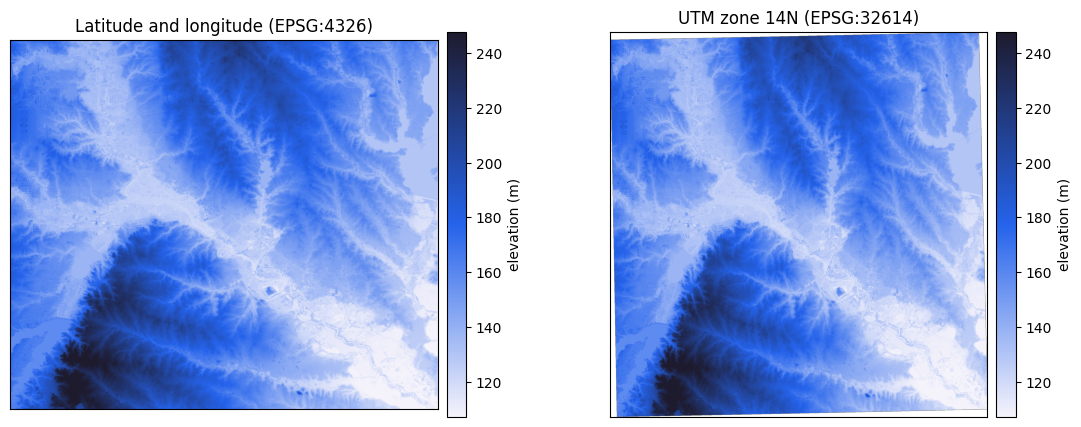

In [12]:
print("before:", dem.rio.crs, round(dem.rio.resolution()[0], 6), "degrees")
print("after: ", dem_utm.rio.crs, round(cell_m, 1), "meters")

lat = float(dem.y.mean())
dx = abs(dem.rio.resolution()[0]) * 111320 * np.cos(np.radians(lat))   # meters per degree of longitude shrinks with cos(latitude)
dy = abs(dem.rio.resolution()[1]) * 110574                              # meters per degree of latitude
print(f"at latitude {lat:.1f}, one lat/lon cell is {dx:.1f} m wide and {dy:.1f} m tall")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
kw = dict(cmap=ELEV, vmin=float(dem.quantile(0.01)), vmax=float(dem.quantile(0.995)))
show(dem, ax[0], "Latitude and longitude (EPSG:4326)", label="elevation (m)", **kw)
show(dem_utm, ax[1], "UTM zone 14N (EPSG:32614)", label="elevation (m)", **kw)
plt.show()

**🔎 Try it yourself.** Reproject `pop` (Mollweide) to `"EPSG:32614"` with `pop.rio.reproject`. What cell size do you get, and does the total number of residents stay the same? Population counts do not survive reprojection exactly, which is why Part 4 is about choosing a method.

## Part 4. Resample: sum, mean, and nearest

**Resampling** changes the cell size. Coarsening replaces each block of cells with one cell, and the rule for combining the block must match what the numbers mean:

- **Counts** (residents per cell) add up. Use the **sum**.
- **Measurements** (elevation, temperature) are summarized with the **mean**.
- **Class codes** (land cover) are labels. Use the **nearest** cell's value. Never average them.

A hand example first: a 4 by 4 block of real population cells, coarsened to 2 by 2.

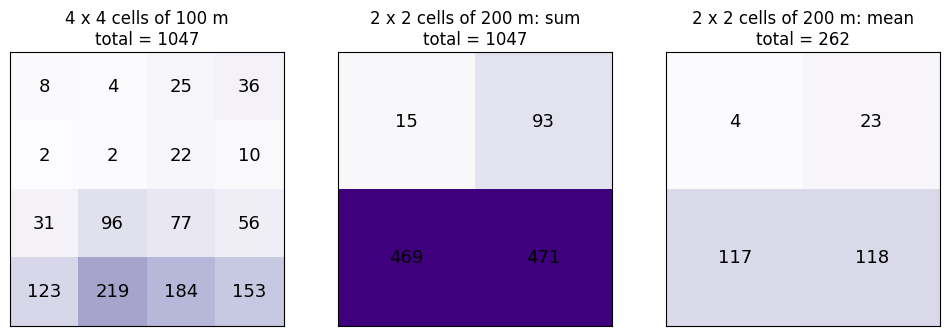

In [13]:
blk = pop.values[50:54, 494:498]
by_sum = blk.reshape(2, 2, 2, 2).sum(axis=(1, 3))
by_mean = blk.reshape(2, 2, 2, 2).mean(axis=(1, 3))
fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
top = by_sum.max()
for a, (arr, t) in zip(ax, [(blk, "4 x 4 cells of 100 m"), (by_sum, "2 x 2 cells of 200 m: sum"), (by_mean, "2 x 2 cells of 200 m: mean")]):
    n = arr.shape[0]
    a.imshow(arr, cmap=SEQ, vmin=0, vmax=top, extent=(0, n, n, 0))
    for r in range(n):
        for c in range(n):
            a.text(c + .5, r + .5, f"{arr[r, c]:.0f}", ha="center", va="center", fontsize=13)
    a.set_title(f"{t}\ntotal = {arr.sum():.0f}"); a.set_xticks([]); a.set_yticks([])
plt.show()

Summing keeps the total. Averaging a block of 4 cells divides the total by 4, so the mean grid reports one quarter of the residents. Now the whole grid, coarsened from 100 m to 1 km cells (blocks of 10 by 10). `coarsen` groups the cells, then `sum` or `mean` combines each group.

In [14]:
ten = pop.coarsen(x=10, y=10, boundary="pad")      # 100 m cells -> 1 km cells
print("residents in the 100 m grid:    ", round(float(pop.sum())))
print("residents after summing 10x10:  ", round(float(ten.sum().sum())))
print("residents after averaging 10x10:", round(float(ten.mean().sum())))

residents in the 100 m grid:     4125256
residents after summing 10x10:   4125256
residents after averaging 10x10: 41361


**Land cover.** `rasterio.enums.Resampling` names the resampling methods that `rio.reproject` accepts. A small window of the land cover map, resampled to 100 m cells with `nearest` and with `bilinear` (a weighted average of the four closest cells), shows what averaging class codes does.

In [15]:
# ESA WorldCover 2021 class codes that occur in this window (0 means no data).
WC = {10: ("Tree cover", "#059669"), 20: ("Shrubland", "#84CC16"), 30: ("Grassland", "#FACC15"),
      40: ("Cropland", "#F59E0B"), 50: ("Built-up", "#DB2777"), 60: ("Bare or sparse", "#B8B0C8"),
      80: ("Permanent water", "#2563EB"), 90: ("Herbaceous wetland", "#7C3AED")}

In [16]:
from rasterio.enums import Resampling

lc_full = rioxarray.open_rasterio("data/dallas_landcover_2021.tif").squeeze(drop=True)
lc = lc_full.rio.clip_box(-96.85, 32.75, -96.75, 32.82)            # a small window, in longitude and latitude
lc_f = lc.astype("float32")
near = lc_f.rio.reproject("EPSG:32614", resolution=100, resampling=Resampling.nearest)
bili = lc_f.rio.reproject("EPSG:32614", resolution=100, resampling=Resampling.bilinear)
codes = set(np.unique(lc.values).tolist())
print("codes in the original window:", sorted(codes))
for name, g in [("nearest", near), ("bilinear", bili)]:
    v = np.unique(np.round(g.values[~np.isnan(g.values)]).astype(int))
    v = v[v > 0]                                       # 0 is the fill value for cells outside the original window
    new = sorted(set(v.tolist()) - codes)
    print(f"{name:9s} codes not in the original: {len(new)}", new[:8])

codes in the original window: [10, 20, 30, 40, 50, 60, 80]
nearest   codes not in the original: 0 []
bilinear  codes not in the original: 49 [11, 12, 13, 14, 15, 16, 17, 18]


Bilinear resampling invents class codes that are not on the map. A code of 45 between 40 (cropland) and 50 (built-up) does not mean anything. Resample categorical rasters with `nearest`.

**🔎 Try it yourself.** Replace `Resampling.nearest` with `Resampling.mode` (the most common class in each output cell). How does the map differ from `nearest`?

## Part 5. Map algebra: arithmetic on grids

**Map algebra** means computing a new raster from one or more rasters, cell by cell. **Local** operations use only the cells at the same position: a comparison (`lc == 50`) gives a mask of True and False, and arithmetic (`pop / volume`) gives a new grid. Grids must share the same cell grid to be combined this way.

**A mask.** Class 50 in WorldCover is built-up land.

In [17]:
built = lc_full == 50          # True where the cell is built-up
print("share of the window that is built-up:", round(float(built.mean()), 3))

# size of one cell in square km at this latitude: a degree of longitude shrinks with cos(latitude)
cell_km2 = abs(lc_full.rio.resolution()[0]) * 111.32 * np.cos(np.radians(32.8)) * abs(lc_full.rio.resolution()[1]) * 110.574
by_class = pd.Series({WC[k][0]: round(float((lc_full == k).sum()) * cell_km2, 1) for k in WC}, name="area (square km)")
by_class

share of the window that is built-up: 0.352


Tree cover            891.9
Shrubland               0.0
Grassland             607.4
Cropland              124.4
Built-up              992.5
Bare or sparse         68.5
Permanent water       130.8
Herbaceous wetland      2.0
Name: area (square km), dtype: float64

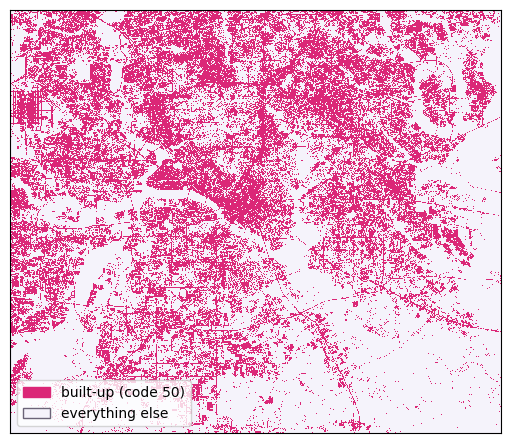

In [18]:
fig, ax = plt.subplots(figsize=(7, 5.5))
small = lc_full.isel(x=slice(None, None, 6), y=slice(None, None, 6))       # every 6th cell, to draw faster
ax.imshow(small.values == 50, cmap=ListedColormap(["#F5F3FB", "#DB2777"]), extent=extent(small), interpolation="nearest")
ax.legend(handles=[Patch(color="#DB2777", label="built-up (code 50)"), Patch(color="#F5F3FB", ec="#6B6478", label="everything else")],
          loc="lower left")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

**Arithmetic on two grids.** Built-up volume is the volume of buildings in each cell, in cubic meters. Dividing residents by built-up volume gives residents per thousand cubic meters of building. Cells with no buildings are masked first so the division does not produce infinities.

grids share one cell grid: True
median: 0.9  99th percentile: 6.9


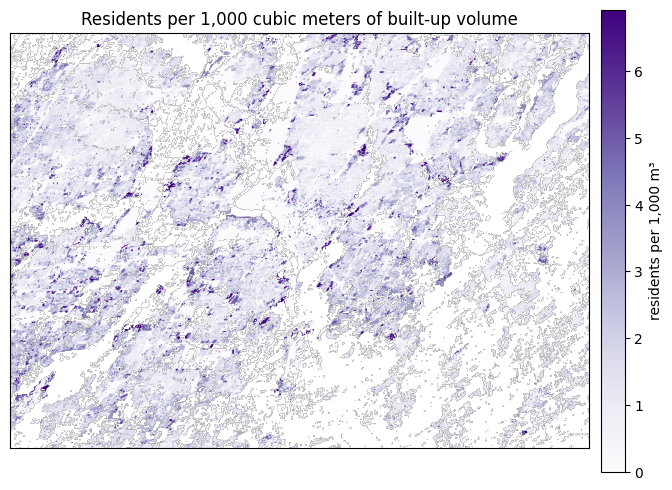

In [19]:
bv = rioxarray.open_rasterio("data/dallas_built_v_2020.tif", masked=True).squeeze(drop=True)
density = 1000 * pop / bv.where(bv > 0)            # residents per 1,000 cubic meters of building
print("grids share one cell grid:", bool((pop.x == bv.x).all() and (pop.y == bv.y).all()))
print("median:", round(float(density.median()), 2), " 99th percentile:", round(float(density.quantile(0.99)), 1))

fig, ax = plt.subplots(figsize=(8, 6))
show(density, ax, "Residents per 1,000 cubic meters of built-up volume", label="residents per 1,000 m³",
     vmax=float(density.quantile(0.99)))
plt.show()

**NDVI** (normalized difference vegetation index) measures how green a cell is, from two bands of a satellite image. Healthy plants reflect a lot of near-infrared light and absorb red light:

$$\text{NDVI} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}}$$

- NIR: the near-infrared band value of the cell.
- Red: the red band value of the cell.
- The numerator is the difference between the two bands. The denominator rescales it so the result runs from -1 to 1.
- Dense vegetation is close to 1. Bare ground, pavement, and roofs are near 0. Water is negative.

Worked example with the two most extreme cells in the downtown window:

In [20]:
s2 = rioxarray.open_rasterio("data/dallas_s2_2025-09-17.tif").assign_coords(band=["blue", "green", "red", "nir"])
red, nir = s2.sel(band="red").astype("float32"), s2.sel(band="nir").astype("float32")
ndvi = (nir - red) / (nir + red)

NDVI range: -0.45 to 1.0
share of cells with NDVI above 0.4: 0.53
greenest cell: red 1 nir 2354 NDVI 1.0
lowest cell:   red 16184 nir 6168 NDVI -0.45


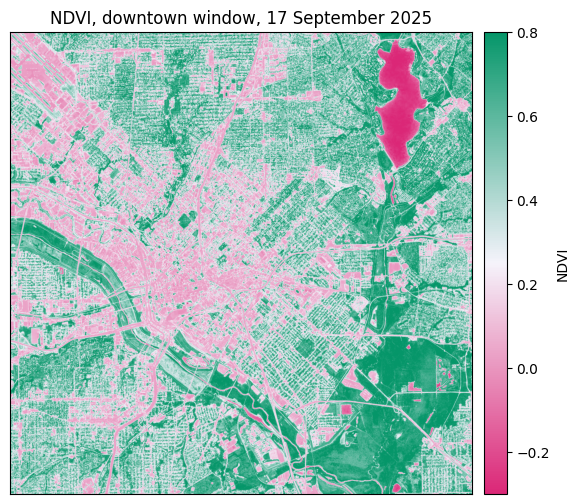

In [21]:
print("NDVI range:", round(float(ndvi.min()), 2), "to", round(float(ndvi.max()), 2))
print("share of cells with NDVI above 0.4:", round(float((ndvi > 0.4).mean()), 2))

iy, ix = np.unravel_index(np.nanargmax(ndvi.values), ndvi.shape)
print("greenest cell: red", int(red.values[iy, ix]), "nir", int(nir.values[iy, ix]), "NDVI", round(float(ndvi.values[iy, ix]), 2))
iy, ix = np.unravel_index(np.nanargmin(ndvi.values), ndvi.shape)
print("lowest cell:   red", int(red.values[iy, ix]), "nir", int(nir.values[iy, ix]), "NDVI", round(float(ndvi.values[iy, ix]), 2))

fig, ax = plt.subplots(figsize=(7.5, 6))
show(ndvi, ax, "NDVI, downtown window, 17 September 2025", cmap=NDVI_CM, label="NDVI", vmin=-0.3, vmax=0.8)
plt.show()

**🔎 Try it yourself.** Make a mask of cells with NDVI above 0.4 and compute its share. Then try `ndvi < 0.1` and look at where those cells fall. What is on the ground there?

## Part 6. Focal operations: a moving window

A **focal** operation computes each output cell from a window of cells around it, such as the 3 by 3 block centered on the cell. Two common uses are **smoothing** (the window mean) and **slope** (the steepness of the surface, from how fast elevation changes between neighbors). The window moves one cell at a time across the whole grid.

Slope in degrees from the rise per meter in each direction:

$$\text{slope} = \arctan\left(\sqrt{\left(\frac{\partial z}{\partial x}\right)^2 + \left(\frac{\partial z}{\partial y}\right)^2}\right)$$

- $z$: elevation in meters.
- $\partial z / \partial x$ and $\partial z / \partial y$: meters of rise per meter of distance eastward and northward, estimated by `numpy.gradient` from neighboring cells. This is why the cell size in meters (Part 3) is needed.
- The square root combines the two directions into the steepest rise per meter.
- $\arctan$ turns rise over run into an angle. A rise of 1 m per 1 m is 45 degrees.

In [22]:
def slope_degrees(elev, cell):
    """Slope in degrees from a 2-D elevation grid in meters with square cells of `cell` meters."""
    dz_dy, dz_dx = np.gradient(elev.values, cell, cell)    # meters of rise per meter of run
    return np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))

99th percentile of slope: 11.9 degrees


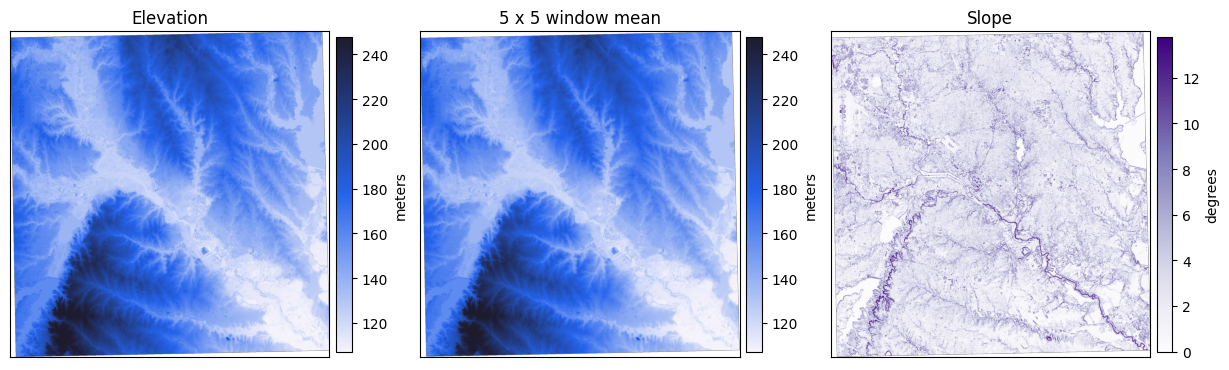

In [23]:
slope = slope_degrees(dem_utm, cell_m)
smooth = dem_utm.rolling(x=5, y=5, center=True).mean()        # 5 x 5 window mean
print("99th percentile of slope:", round(float(np.nanpercentile(slope, 99)), 1), "degrees")

d = dem_utm
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
lim = dict(vmin=float(d.quantile(0.01)), vmax=float(d.quantile(0.995)))
show(d, ax[0], "Elevation", cmap=ELEV, label="meters", **lim)
show(smooth, ax[1], "5 x 5 window mean", cmap=ELEV, label="meters", **lim)
im = ax[2].imshow(slope, cmap=SEQ, extent=extent(d), vmax=float(np.nanpercentile(slope, 99.5)))
fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.02, label="degrees"); ax[2].set_title("Slope")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.show()

**🔎 Try it yourself.** Change the window to `x=15, y=15`. Smoothing removes small bumps. What happens to the map, and what would happen to the steepest slopes if you computed slope from the smoothed grid?

## Part 7. Zonal statistics: summarize a grid by tract

A **zonal statistic** summarizes the cells of a raster that fall inside each zone (here, each tract). It needs two grids of the same shape: the values (residents per cell) and the zones (the tract each cell belongs to). `rasterio.features.rasterize` builds the zone grid by burning each tract's number into the cells it covers, and `numpy.bincount` then adds up the values for each number. The helper below does both and is the only zonal code in this lab.

The statistic must match the data. Residents are counts, so the tract total is the **sum** of its cells. A mean would give the average cell, which says nothing about how many people live in the tract.

In [24]:
from rasterio import features


def zonal_sum(grid, zones):
    """Sum the cells of a 2-D raster inside each polygon.

    grid:  2-D DataArray (NaN cells count as 0).
    zones: GeoDataFrame in the same CRS as the grid.
    Returns one total per row of `zones`, in order. A cell belongs to the polygon that contains its center.
    """
    ids = features.rasterize(((geom, i + 1) for i, geom in enumerate(zones.geometry)),
                             out_shape=grid.shape, transform=grid.rio.transform(), fill=0, dtype="int32")
    totals = np.bincount(ids.ravel(), weights=np.nan_to_num(grid.values).ravel(), minlength=len(zones) + 1)
    return totals[1:]

In [25]:
tracts["grid_pop"] = zonal_sum(pop, tracts)
print("grid total:", round(float(tracts.grid_pop.sum())), " ACS total:", int(tracts.pop_total.sum()))
tracts[["GEOID", "grid_pop", "pop_total"]].head(3).round(0)

grid total: 2591863  ACS total: 2442057


,GEOID,grid_pop,pop_total
0,48113016638,1828.0,2073
1,48113013630,2308.0,2197
2,48113012211,4656.0,4679


**Check the result.** The grid is a model that spreads census counts onto cells using building data. The ACS is a survey estimate. They should agree broadly and differ in places. A scatter plot against the line of equal values shows both.

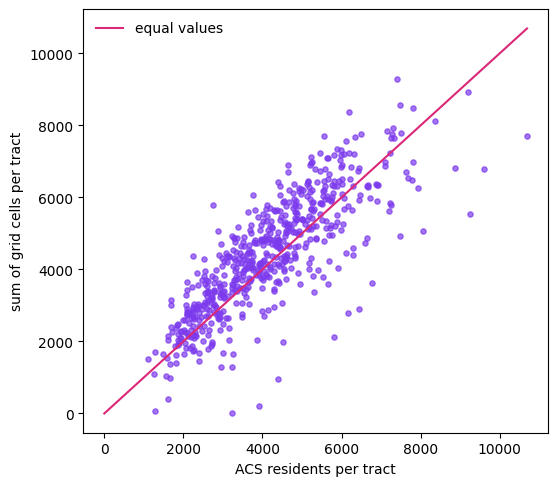

correlation: 0.81


,GEOID,grid_pop,pop_total,diff
51,48113014002,204.0,3907,-3703.0
385,48113019042,5550.0,9251,-3701.0
151,48113014144,2114.0,5800,-3686.0
279,48113018159,2915.0,6435,-3520.0
188,48113014143,955.0,4402,-3447.0


In [26]:
r = np.corrcoef(tracts.grid_pop, tracts.pop_total)[0, 1]
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(tracts.pop_total, tracts.grid_pop, s=14, color="#7C3AED", alpha=.7)
m = max(tracts.pop_total.max(), tracts.grid_pop.max())
ax.plot([0, m], [0, m], color="#DB2777", lw=1.5, label="equal values")
ax.set_xlabel("ACS residents per tract"); ax.set_ylabel("sum of grid cells per tract"); ax.legend(frameon=False)
plt.show()
print("correlation:", round(r, 2))

tracts["diff"] = tracts.grid_pop - tracts.pop_total
tracts.loc[tracts["diff"].abs().sort_values(ascending=False).index[:5], ["GEOID", "grid_pop", "pop_total", "diff"]].round(0)

**🔎 Try it yourself.** Make a choropleth of `grid_pop` and one of `pop_total` with `tracts.plot(..., scheme="quantiles", legend=True)`. Where do the two maps differ most?

## Part 8. Cell size changes the answer

The same people, summarized with bigger cells, look less concentrated. Set a density cutoff of 2,500 residents per square km. For each cell size, coarsen the grid with a sum, convert counts to density, and compute the share of all residents who live in cells above the cutoff.

In [27]:
cutoff = 2500                                               # residents per square km
for k in (1, 5, 10, 30):
    coarse = pop.coarsen(x=k, y=k, boundary="pad").sum()    # k x k block sums
    km2 = (100 * k / 1000) ** 2                             # area of one coarse cell in square km
    dense = coarse / km2 > cutoff
    share = float(coarse.where(dense).sum() / coarse.sum())
    print(f"{100 * k:>5} m cells: {100 * share:4.1f}% of residents in cells above {cutoff}/km²")

  100 m cells: 71.1% of residents in cells above 2500/km²
  500 m cells: 54.2% of residents in cells above 2500/km²
 1000 m cells: 42.2% of residents in cells above 2500/km²
 3000 m cells: 22.6% of residents in cells above 2500/km²


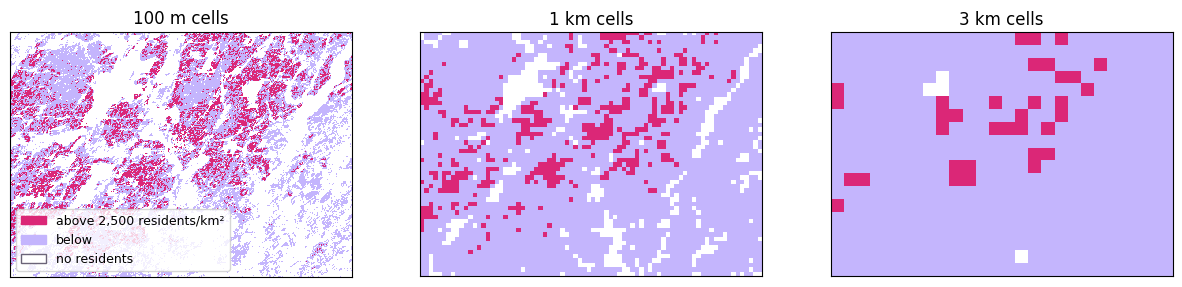

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
for a, k, lab in zip(ax, (1, 10, 30), ("100 m cells", "1 km cells", "3 km cells")):
    coarse = pop.coarsen(x=k, y=k, boundary="pad").sum()
    dens = coarse / ((100 * k / 1000) ** 2)
    a.imshow(np.where(dens.values > cutoff, 1, np.where(dens.values > 0, 0, np.nan)),
             cmap=ListedColormap(["#C4B5FD", "#DB2777"]), extent=extent(coarse), interpolation="nearest")
    a.set_title(lab); a.set_xticks([]); a.set_yticks([])
ax[0].legend(handles=[Patch(color="#DB2777", label=f"above {cutoff:,} residents/km²"), Patch(color="#C4B5FD", label="below"),
                      Patch(fc="white", ec="#6B6478", label="no residents")],
             loc="lower left", fontsize=9)
plt.show()

No cell size is correct. The share falls steadily because a big cell averages dense blocks together with empty land. This is the raster version of the modifiable areal unit problem: the answer depends on the grid you chose. Report the cell size with any statistic computed from a raster.

**🔎 Try it yourself.** Lower the cutoff to 1,000 residents per square km. Does the share still fall as cells get larger? Does it fall by as much?

## Learn More / Going Further

- **`xvec`.** The package `xvec` computes zonal statistics in one call: `pop.xvec.zonal_stats(tracts.geometry, x_coords="x", y_coords="y", stats="sum")` (not run here, it is not installed in this kernel). It also supports `mean`, `median`, `min`, and `max`. Compare its totals with `zonal_sum`.
- **Rasterize a road or a single tract.** `rasterio.features.rasterize` at 100 m, 500 m, and 1 km, then compare the area of the burned cells with the true area of the polygon.
- **More bands.** Build a false-color image of the Sentinel-2 window with near-infrared, red, and green as the red, green, and blue channels. Vegetation turns bright red.
- **Compare two grids.** Mask NDVI to cells below 0.1 and ask what share of them the land cover map labels built-up. The two grids have different cell sizes, so reproject one to match the other with `rio.reproject_match`.
- **Another country.** WorldPop publishes 100 m population grids for every country. Open one for Kenya, clip it, and repeat Parts 1 and 2.
- **Big rasters.** Cloud Optimized GeoTIFFs and STAC catalogs let you read only the window you need from a remote file. The Sentinel-2 file here was cut that way from a 10,980 by 10,980 cell scene.
- **Stretch challenge.** For each tract, compute the mean NDVI (a measurement, so the mean is right) and the total population (a count, so the sum is right). Which tracts are dense and green?

**Sources.** GHS-POP and GHS-BUILT-V: Schiavina et al. (2023), GHSL Data Package 2023, European Commission Joint Research Centre, doi:10.2760/098587. ESA WorldCover 2021 v200: Zanaga et al. (2022), doi:10.5281/zenodo.7254221. Copernicus GLO-30 DEM and Sentinel-2 L2A: European Space Agency and Copernicus, via the Earth Search catalog. ACS 2020-2024: US Census Bureau. Rey, Arribas-Bel and Wolf (2023), *Geographic Data Science with Python*, "Spatial Data".